In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")

In [2]:
DATA_PATH = "../data/engineered_data.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Shape: (3011, 18)

Columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'SMA_7', 'SMA_14', 'Volatility_7', 'RSI_14', 'MACD', 'MACD_Signal', 'Lag_1', 'Lag_2', 'Lag_3', 'Volume_Change', 'Target']


,Date,Open,High,Low,Close,Volume,Return,SMA_7,SMA_14,Volatility_7,RSI_14,MACD,MACD_Signal,Lag_1,Lag_2,Lag_3,Volume_Change,Target
0,2013-12-27,763.280029,777.510010,713.599976,735.070007,46862700.000000,-0.035316,677.298567,694.134282,0.059191,49.915908,-25.829491,-20.818665,761.979980,682.210022,665.580017,inf,727.830017
1,2013-12-28,737.979980,747.059998,705.349976,727.830017,32505800.000000,-0.009849,694.751430,683.793570,0.056262,49.465334,-22.581305,-21.171193,735.070007,761.979980,682.210022,-0.306361,745.049988
2,2013-12-29,728.049988,748.609985,714.440002,745.049988,19011300.000000,0.023659,713.018572,674.431427,0.056167,50.607340,-18.405421,-20.618038,727.830017,735.070007,761.979980,-0.415141,756.130005
3,2013-12-30,741.349976,766.599976,740.239990,756.130005,20707700.000000,0.014872,724.835720,678.014287,0.048943,51.368868,-14.040092,-19.302449,745.049988,727.830017,735.070007,0.089231,754.010010
4,2013-12-31,760.320007,760.580017,738.169983,754.010010,20897300.000000,-0.002804,737.468576,683.149288,0.048171,51.206191,-10.629078,-17.567775,756.130005,745.049988,727.830017,0.009156,771.400024


In [3]:
# Convert Date from string to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

print("Date range:")
print(df["Date"].min(), "→", df["Date"].max())

print("\nShape:", df.shape)

Date range:
2013-12-27 00:00:00 → 2022-10-16 00:00:00

Shape: (3011, 18)


In [4]:
# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

print("Missing values after replacing infinity:")
print(df.isnull().sum())

Missing values after replacing infinity:
Date             0
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    1
Target           0
dtype: int64


In [5]:
# Replace infinite values with NaN
df = df.replace([np.inf, -np.inf], np.nan)

print("Missing values after replacing infinity:")
print(df.isnull().sum())

Missing values after replacing infinity:
Date             0
Open             0
High             0
Low              0
Close            0
Volume           0
Return           0
SMA_7            0
SMA_14           0
Volatility_7     0
RSI_14           0
MACD             0
MACD_Signal      0
Lag_1            0
Lag_2            0
Lag_3            0
Volume_Change    1
Target           0
dtype: int64


In [6]:
df["Volume_Change"] = df["Volume_Change"].fillna(0)

print("Total missing values:", df.isnull().sum().sum())

print(
    "Total infinite values:",
    np.isinf(
        df.select_dtypes(include=np.number)
    ).sum().sum()
)

Total missing values: 0
Total infinite values: 0


In [7]:
target_check = np.isclose(
    df["Target"].iloc[:-1].values,
    df["Close"].iloc[1:].values
)

print(
    "Target matches next-day Close:",
    target_check.mean() * 100,
    "%"
)

Target matches next-day Close: 100.0 %


In [8]:
FEATURES = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Return",
    "SMA_7",
    "SMA_14",
    "Volatility_7",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "Volume_Change"
]

TARGET = "Target"

print("Number of features:", len(FEATURES))
print("\nFeatures:")
for feature in FEATURES:
    print("-", feature)

print("\nTarget:", TARGET)

Number of features: 13

Features:
- Open
- High
- Low
- Close
- Volume
- Return
- SMA_7
- SMA_14
- Volatility_7
- RSI_14
- MACD
- MACD_Signal
- Volume_Change

Target: Target


In [9]:
df[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
Open,3011.000000,10418.708869,15391.066163,176.897003,576.005981,4465.540000,10209.525195,67549.735581
High,3011.000000,10692.696833,15794.217357,211.731003,583.275024,4626.520020,10420.076954,68789.625939
Low,3011.000000,10118.692481,14930.677270,171.509995,565.700989,4343.980000,9942.100001,66382.061008
Close,3011.000000,10431.473484,15399.569087,178.102997,575.998993,4565.299805,10232.671727,67566.830088
Volume,3011.000000,13406249847.187620,19268219855.000378,2857830.000000,55643850.000000,4139364828.952230,23133104315.880898,350967941479.059998
Return,3011.000000,0.001885,0.040063,-0.371695,-0.013782,0.001542,0.018266,0.252472
SMA_7,3011.000000,10412.997151,15376.816091,204.545569,578.732574,4463.474346,10271.729746,65425.441580
SMA_14,3011.000000,10390.215615,15350.919242,222.873070,581.183435,4443.858573,10161.174878,63757.951663
Volatility_7,3011.000000,0.033922,0.021413,0.001998,0.018407,0.029356,0.044249,0.158796
RSI_14,3011.000000,52.744595,14.259883,9.920237,42.578237,51.575181,61.998307,94.302215


In [10]:
date_diff = df["Date"].diff().dt.days

print("Date gap distribution:")
print(date_diff.value_counts().sort_index())

print("\nNumber of gaps greater than 1 day:")
print((date_diff > 1).sum())

Date gap distribution:
Date
1.000000    2905
2.000000      72
3.000000       6
4.000000       5
5.000000       7
6.000000      12
7.000000       3
Name: count, dtype: int64

Number of gaps greater than 1 day:
105


In [11]:
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("Dataset sizes")
print("----------------")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

print("\nDate ranges")
print("----------------")
print(
    "Train      :",
    train_df["Date"].min(),
    "→",
    train_df["Date"].max()
)

print(
    "Validation :",
    val_df["Date"].min(),
    "→",
    val_df["Date"].max()
)

print(
    "Test       :",
    test_df["Date"].min(),
    "→",
    test_df["Date"].max()
)

Dataset sizes
----------------
Train      : 2107
Validation : 452
Test       : 452

Date ranges
----------------
Train      : 2013-12-27 00:00:00 → 2019-10-03 00:00:00
Validation : 2019-10-04 00:00:00 → 2021-01-07 00:00:00
Test       : 2021-01-08 00:00:00 → 2022-10-16 00:00:00


In [12]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

# Fit ONLY on training data
train_df[FEATURES] = feature_scaler.fit_transform(
    train_df[FEATURES]
)

# Transform validation and test using the training scaler
val_df[FEATURES] = feature_scaler.transform(
    val_df[FEATURES]
)

test_df[FEATURES] = feature_scaler.transform(
    test_df[FEATURES]
)

# Target scaling
train_df[[TARGET]] = target_scaler.fit_transform(
    train_df[[TARGET]]
)

val_df[[TARGET]] = target_scaler.transform(
    val_df[[TARGET]]
)

test_df[[TARGET]] = target_scaler.transform(
    test_df[[TARGET]]
)

print("Scaling completed.")

Scaling completed.


In [13]:
print("Training feature means:")
print(train_df[FEATURES].mean().round(3))

print("\nTraining feature standard deviations:")
print(train_df[FEATURES].std().round(3))

Training feature means:
Open             0.000000
High            -0.000000
Low              0.000000
Close            0.000000
Volume          -0.000000
Return           0.000000
SMA_7            0.000000
SMA_14           0.000000
Volatility_7     0.000000
RSI_14          -0.000000
MACD            -0.000000
MACD_Signal     -0.000000
Volume_Change    0.000000
dtype: float64

Training feature standard deviations:
Open            1.000000
High            1.000000
Low             1.000000
Close           1.000000
Volume          1.000000
Return          1.000000
SMA_7           1.000000
SMA_14          1.000000
Volatility_7    1.000000
RSI_14          1.000000
MACD            1.000000
MACD_Signal     1.000000
Volume_Change   1.000000
dtype: float64


In [14]:
LOOKBACK = 30

def create_sequences(data, features, target, lookback=30):
    X = []
    y = []
    dates = []

    values = data[features].values
    targets = data[target].values
    date_values = data["Date"].values

    for i in range(lookback, len(data)):

        # Check that the previous 30 observations
        # represent 30 consecutive calendar days
        window_dates = pd.to_datetime(
            date_values[i-lookback:i]
        )

        expected_dates = pd.date_range(
            start=window_dates[0],
            periods=lookback,
            freq="D"
        )

        if not window_dates.equals(expected_dates):
            continue

        X.append(values[i-lookback:i])
        y.append(targets[i])
        dates.append(date_values[i])

    return (
        np.array(X),
        np.array(y),
        np.array(dates)
    )

In [15]:
X_train, y_train, train_dates = create_sequences(
    train_df,
    FEATURES,
    TARGET,
    LOOKBACK
)

X_val, y_val, val_dates = create_sequences(
    val_df,
    FEATURES,
    TARGET,
    LOOKBACK
)

X_test, y_test, test_dates = create_sequences(
    test_df,
    FEATURES,
    TARGET,
    LOOKBACK
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2077, 30, 13)
y_train: (2077,)

X_val: (229, 30, 13)
y_val: (229,)

X_test: (20, 30, 13)
y_test: (20,)


In [16]:
print("First training sample:")
print(X_train[0])

print("\nFirst target:")
print(y_train[0])

print("\nFirst prediction date:")
print(train_dates[0])

First training sample:
[[-6.35912685e-01 -6.34092077e-01 -6.49548165e-01 -6.44032184e-01
  -5.65007835e-01 -9.50227652e-01 -6.58851068e-01 -6.53744099e-01
   1.21650040e+00 -2.04054998e-01 -1.76496986e-01 -1.73241225e-01
  -1.51741172e-01]
 [-6.42558560e-01 -6.41827751e-01 -6.51806380e-01 -6.45933410e-01
  -5.67355521e-01 -3.00010986e-01 -6.54250536e-01 -6.56481446e-01
   1.08250944e+00 -2.35554919e-01 -1.66125778e-01 -1.74435798e-01
  -7.28039254e-01]
 [-6.45166993e-01 -6.41433985e-01 -6.49318230e-01 -6.41411436e-01
  -5.69562184e-01  5.55542697e-01 -6.49435361e-01 -6.58959751e-01
   1.07817891e+00 -1.55716483e-01 -1.52792500e-01 -1.72561384e-01
  -9.32666924e-01]
 [-6.41673322e-01 -6.36863717e-01 -6.42256180e-01 -6.38501817e-01
  -5.69284783e-01  3.31169649e-01 -6.46320390e-01 -6.58011313e-01
   7.47769203e-01 -1.02477504e-01 -1.38854340e-01 -1.68103390e-01
   1.61122706e-02]
 [-6.36690231e-01 -6.38393058e-01 -6.42822788e-01 -6.39058529e-01
  -5.69253779e-01 -1.20119683e-01 -6.429903

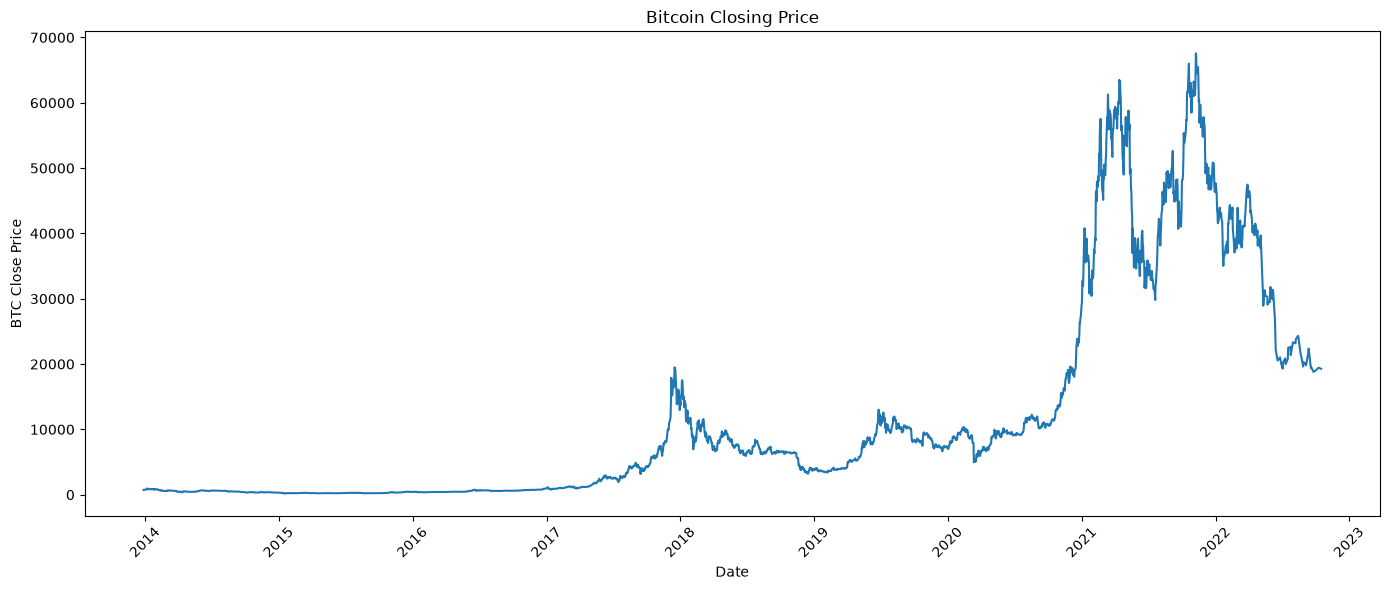

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(df["Date"], df["Close"])

plt.title("Bitcoin Closing Price")
plt.xlabel("Date")
plt.ylabel("BTC Close Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()